# Dos formas de conectar el lazo de Nb

Señal que llega al analizador pasando por toda la cadena de filtrado:

generador (50 Ω) → ambiente → crio → lazo de Nb → crio → ambiente → analizador (50 Ω)

El generador entra por una línea y el analizador mide a la salida de otra. La malla de los
coaxiales va a tierra. Se comparan dos formas de cerrar el lazo en el portamuestras:

- Conexión 1: + con − del mismo canal (líneas 3 y 4).
- Conexión 2: + con + y − con − de dos canales distintos (3 con 11, 4 con 12).

En las dos el lazo es solo el alambre de Nb (superconductor), sin ninguna carga. Todo lo demás
(filtros, generador, analizador) es igual; lo único que cambia es qué líneas se unen.

Cada una se calcula con el filtro crio y sin él, para ver cuánto aporta el crio.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

## Valores

Filtro ambiente por línea: R, C a tierra, R, C a tierra. Las dos conexiones usan líneas con el
mismo ambiente: según el Cuadro 1, las líneas 3, 4, 11 y 12 tienen 15 Ω / 1 µF.

Filtro crio por canal: 3 R de 22 Ω en cada línea y 2 C de 47 nF entre + y −.

In [2]:
AMBIENTE = {3: (15, 1e-6), 4: (15, 1e-6), 11: (15, 1e-6), 12: (15, 1e-6)}   # línea: (R, C)
R_cry = 22.0
C_cry = 47e-9
R_gen = 50.0
R_an = 50.0
CABLE = 1e-6                     # Ω, un cable (Nb superconductor)

f = np.logspace(1, 6, 501)       # 10 Hz a 1 MHz

## Modelo

Se resuelve el circuito entero por nodos (leyes de Kirchhoff) a cada frecuencia. Cada
componente es (nodo, nodo, impedancia) y "GND" es tierra.

In [3]:
def resolver(frec, comps, entrada, salida, R_fuente=R_gen):
    """Voltaje en el nodo 'salida' con un generador de 1 V (y R_fuente) en el nodo 'entrada'."""
    w = 2 * np.pi * frec
    nodos = {"GND": 0}
    for a, b, _ in comps:
        nodos.setdefault(a, len(nodos))
        nodos.setdefault(b, len(nodos))
    Y = np.zeros((len(nodos), len(nodos)), dtype=complex)
    for a, b, Z in comps + [(entrada, "GND", R_fuente)]:
        z = Z(w) if callable(Z) else Z
        i, j = nodos[a], nodos[b]
        Y[i, i] += 1 / z
        Y[j, j] += 1 / z
        Y[i, j] -= 1 / z
        Y[j, i] -= 1 / z
    I = np.zeros(len(nodos), dtype=complex)
    I[nodos[entrada]] = 1 / R_fuente
    V = np.linalg.solve(Y[1:, 1:], I[1:])
    return V[nodos[salida] - 1]

def cap(C):
    return lambda w: 1 / (1j * w * C)

def ambiente(L):
    R, C = AMBIENTE[L]
    return [(f"ext{L}", f"amb{L}", R), (f"amb{L}", "GND", cap(C)),
            (f"amb{L}", f"ci{L}", R), (f"ci{L}", "GND", cap(C))]

def crio(mas, menos, con_crio=True):
    if not con_crio:
        return [(f"ci{L}", f"pm{L}", CABLE) for L in (mas, menos)]
    comps = []
    for L in (mas, menos):
        comps += [(f"ci{L}", f"a{L}", R_cry), (f"a{L}", f"b{L}", R_cry), (f"b{L}", f"pm{L}", R_cry)]
    comps += [(f"a{mas}", f"a{menos}", cap(C_cry)), (f"b{mas}", f"b{menos}", cap(C_cry))]
    return comps

Las dos conexiones. La transferencia se da como H = 2 V_an / V_gen, así 0 dB es el generador
conectado directo al analizador.

In [4]:
def conexion_1(frec, con_crio=True):
    """+ con − del mismo canal: entra por la línea 3, sale por la 4 (la vuelta del mismo canal)."""
    comps = ambiente(3) + ambiente(4) + crio(3, 4, con_crio)
    comps += [("pm3", "pm4", CABLE),             # Nb en corto
              ("ext4", "GND", R_an)]
    return 2 * resolver(frec, comps, "ext3", "ext4")

def conexion_2(frec, con_crio=True):
    """+ con + y − con − de dos canales: entra por la 3, sale por la 11. Las líneas − (4 y 12)
    van a la malla del lado de afuera."""
    comps = []
    for L in (3, 4, 11, 12):
        comps += ambiente(L)
    comps += crio(3, 4, con_crio) + crio(11, 12, con_crio)
    comps += [("pm3", "pm11", CABLE), ("pm4", "pm12", CABLE),   # Nb
              ("ext4", "GND", CABLE), ("ext12", "GND", CABLE),  # − a la malla
              ("ext11", "GND", R_an)]
    return 2 * resolver(frec, comps, "ext3", "ext11")

def dB(H):
    return 20 * np.log10(np.abs(H))

def fc(funcion):
    """Frecuencia donde la señal cae 3 dB respecto de su valor a 1 Hz."""
    nivel = dB(funcion(1.0))
    return 10 ** brentq(lambda x: dB(funcion(10**x)) - nivel + 3.01, 0.5, 7)

Como control, el canal crio solo, con fuente ideal y salida abierta, tiene que cortar en 28,8 kHz.

In [5]:
def crio_solo(frec):
    comps = crio(1, 2) + [("ci2", "GND", CABLE), ("pm2", "GND", 1e12), ("pm1", "GND", 1e12)]
    return (resolver(frec, comps, "ci1", "pm1", R_fuente=1e-9)
            - resolver(frec, comps, "ci1", "pm2", R_fuente=1e-9))

print(f"f_c del crio solo: {fc(crio_solo) / 1e3:.1f} kHz")

f_c del crio solo: 28.8 kHz


## Resultados

Sin crio las dos conexiones dan la misma curva, así que se dibuja una sola. El punto sobre cada
curva marca su f_c, donde la señal cae 3 dB respecto de su valor a 1 Hz. A la derecha, ampliada
la zona de la f_c.

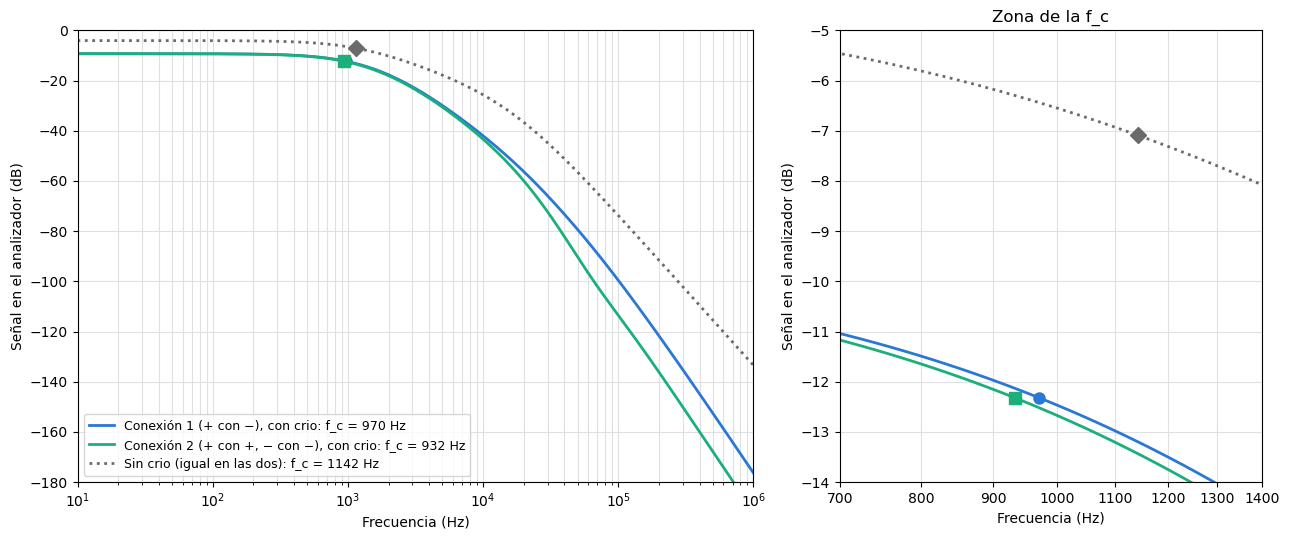

In [6]:
curvas = {
    "Conexión 1 (+ con −), con crio":          (conexion_1, True,  "#2a78d6", "-",  "o"),
    "Conexión 2 (+ con +, − con −), con crio": (conexion_2, True,  "#1baf7a", "-",  "s"),
    "Sin crio (igual en las dos)":             (conexion_1, False, "#6b6b6b", ":",  "D"),
}
dBs = {n: np.array([dB(fun(x, c)) for x in f]) for n, (fun, c, *_) in curvas.items()}
fcs = {n: fc(lambda x: fun(x, c)) for n, (fun, c, *_) in curvas.items()}

fig, (ax, zoom) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
for n, (fun, c, color, estilo, marca) in curvas.items():
    for a in (ax, zoom):
        a.semilogx(f, dBs[n], color=color, linestyle=estilo, linewidth=2,
                   label=f"{n}: f_c = {fcs[n]:.0f} Hz")
        a.plot(fcs[n], dB(fun(1.0, c)) - 3.01, marca, color=color, markersize=8)
ax.set_xlim(10, 1e6)
ax.set_ylim(-180, 0)
zoom.set_xlim(700, 1400)
zoom.set_ylim(-14, -5)
zoom.set_xticks([700, 800, 900, 1000, 1100, 1200, 1300, 1400])
zoom.set_xticklabels(["700", "800", "900", "1000", "1100", "1200", "1300", "1400"])
zoom.minorticks_off()
for a in (ax, zoom):
    a.set_xlabel("Frecuencia (Hz)")
    a.set_ylabel("Señal en el analizador (dB)")
    a.grid(which="both", color="#e0e0e0")
ax.legend(loc="lower left", fontsize=9)
zoom.set_title("Zona de la f_c")
plt.tight_layout()
plt.show()

Diferencia entre con crio y sin crio en cada conexión, o sea lo que agrega el filtro crio. Las
líneas verticales marcan la f_c con crio de cada conexión.

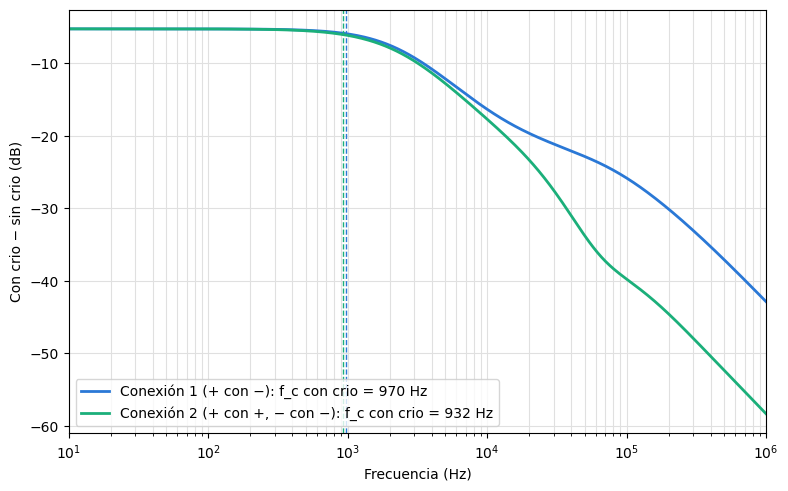

In [7]:
sin = dBs["Sin crio (igual en las dos)"]
fig, ax = plt.subplots(figsize=(9, 5.5))
for n in ["Conexión 1 (+ con −), con crio", "Conexión 2 (+ con +, − con −), con crio"]:
    color = curvas[n][2]
    ax.semilogx(f, dBs[n] - sin, color=color, linewidth=2,
                label=f"{n.replace(', con crio', '')}: f_c con crio = {fcs[n]:.0f} Hz")
    ax.axvline(fcs[n], color=color, linestyle="--", linewidth=1)
ax.set_xlim(10, 1e6)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Con crio − sin crio (dB)")
ax.grid(which="both", color="#e0e0e0")
ax.legend(loc="lower left")
plt.show()

In [8]:
casos = {
    "Conexión 1, con crio": (conexion_1, True),
    "Conexión 1, sin crio": (conexion_1, False),
    "Conexión 2, con crio": (conexion_2, True),
    "Conexión 2, sin crio": (conexion_2, False),
}
filas = []
for nombre, (fun, c) in casos.items():
    H = lambda x: fun(x, c)
    filas.append({"caso": nombre,
                  "nivel a 1 Hz (dB)": round(dB(H(1.0)), 1),
                  "f_c (Hz)": round(fc(H)),
                  "a 10 kHz (dB)": round(dB(H(1e4)), 1),
                  "a 100 kHz (dB)": round(dB(H(1e5)), 1)})
pd.DataFrame(filas).set_index("caso")

,nivel a 1 Hz (dB),f_c (Hz),a 10 kHz (dB),a 100 kHz (dB)
caso,,,,
"Conexión 1, con crio",-9.3,970,-42.0,-99.6
"Conexión 1, sin crio",-4.1,1142,-25.7,-73.8
"Conexión 2, con crio",-9.3,932,-43.4,-113.5
"Conexión 2, sin crio",-4.1,1142,-25.7,-73.8


## Qué se ve

- Sin crio las dos conexiones dan la misma curva (f_c 1142 Hz). Es lo esperable: sin el crio,
  en los dos casos la señal recorre lo mismo.
- Con crio las dos tienen la misma señal a baja frecuencia (−9,3 dB). El crio baja unos 5 dB por
  las resistencias que agrega en serie.
- La f_c con crio es 970 Hz en la conexión 1 y 932 Hz en la 2.
- Lo que agrega el crio a 10 kHz: −16 dB en la conexión 1 y −18 dB en la 2. A 100 kHz: −26 dB en
  la conexión 1 y −40 dB en la 2.
- La diferencia aparece a alta frecuencia. En la conexión 1 los capacitores del crio quedan entre
  la línea de ida y la de vuelta, así que no derivan la señal a tierra. En la conexión 2 cada
  capacitor queda entre la línea de la señal y la línea −, que va a tierra.